# CIFAR-10 / ResNet-20
## Compare optimizers over 5 seeds (mean ± std)

In [1]:
from stepback.plot_utils import load_sweep, plot_val_acc_vs_lr, plot_val_acc_vs_epoch_seeds, _display_name
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [2]:
import pandas as pd

OUTPUT_DIR = "/mnt/ceph/users/tparshakova/step-back/output/"
R1 = load_sweep("cifar10_resnet20_compare_seeds", output_dir=OUTPUT_DIR)
R2 = load_sweep("cifar10_resnet20_compare_seeds_remaining", output_dir=OUTPUT_DIR)

# Merge: concatenate raw_df, rebuild base_df and id_df
R1.raw_df = pd.concat([R1.raw_df, R2.raw_df], ignore_index=True)
R1.id_df = pd.concat([R1.id_df, R2.id_df])
R1.id_df = R1.id_df[~R1.id_df.index.duplicated(keep="first")]
R1.base_df = R1._build_base_df(agg="mean")

R = R1
R.id_df

/mnt/home/tparshakova/Documents/step-back/stepback/record.py:71: UserWarning: Loading from multiple output files. Contents will be merged.
  warnings.warn("Loading from multiple output files. Contents will be merged.")


Creating Record with ID cifar10_resnet20_compare_seeds-000.
Loading data from /mnt/ceph/users/tparshakova/step-back/output/cifar10_resnet20_compare_seeds-000
Loading data from /mnt/ceph/users/tparshakova/step-back/output/cifar10_resnet20_compare_seeds-001
Loading data from /mnt/ceph/users/tparshakova/step-back/output/cifar10_resnet20_compare_seeds-002
Loading data from /mnt/ceph/users/tparshakova/step-back/output/cifar10_resnet20_compare_seeds-003
Loading data from /mnt/ceph/users/tparshakova/step-back/output/cifar10_resnet20_compare_seeds-004
Loading data from /mnt/ceph/users/tparshakova/step-back/output/cifar10_resnet20_compare_seeds-005
Loading data from /mnt/ceph/users/tparshakova/step-back/output/cifar10_resnet20_compare_seeds-006
Loading data from /mnt/ceph/users/tparshakova/step-back/output/cifar10_resnet20_compare_seeds-007
Loading data from /mnt/ceph/users/tparshakova/step-back/output/cifar10_resnet20_compare_seeds-008
Loading data from /mnt/ceph/users/tparshakova/step-back/ou

/mnt/home/tparshakova/Documents/step-back/stepback/record.py:71: UserWarning: Loading from multiple output files. Contents will be merged.
  warnings.warn("Loading from multiple output files. Contents will be merged.")


Creating Record with ID cifar10_resnet20_compare_seeds_remaining-000.
Loading data from /mnt/ceph/users/tparshakova/step-back/output/cifar10_resnet20_compare_seeds_remaining-000
Loading data from /mnt/ceph/users/tparshakova/step-back/output/cifar10_resnet20_compare_seeds_remaining-001
Loading data from /mnt/ceph/users/tparshakova/step-back/output/cifar10_resnet20_compare_seeds_remaining-002
Loading data from /mnt/ceph/users/tparshakova/step-back/output/cifar10_resnet20_compare_seeds_remaining-003
Loading data from /mnt/ceph/users/tparshakova/step-back/output/cifar10_resnet20_compare_seeds_remaining-004
Loading data from /mnt/ceph/users/tparshakova/step-back/output/cifar10_resnet20_compare_seeds_remaining-005
Loading data from /mnt/ceph/users/tparshakova/step-back/output/cifar10_resnet20_compare_seeds_remaining-006
Loading data from /mnt/ceph/users/tparshakova/step-back/output/cifar10_resnet20_compare_seeds_remaining-007
Loading data from /mnt/ceph/users/tparshakova/step-back/output/cif

,name,lr,lr_schedule,momentum,ns_steps,weight_decay,only_train_matrices
name=muon:lr=1e-05:lr_schedule=constant:momentum=0.95:ns_steps=5:weight_decay=0,muon,1e-05,constant,0.95,5,0,none
name=muon:lr=3e-05:lr_schedule=constant:momentum=0.95:ns_steps=5:weight_decay=0,muon,3e-05,constant,0.95,5,0,none
name=muon:lr=0.0001:lr_schedule=constant:momentum=0.95:ns_steps=5:weight_decay=0,muon,0.0001,constant,0.95,5,0,none
name=muon:lr=0.0003:lr_schedule=constant:momentum=0.95:ns_steps=5:weight_decay=0,muon,0.0003,constant,0.95,5,0,none
name=muon:lr=0.001:lr_schedule=constant:momentum=0.95:ns_steps=5:weight_decay=0,muon,0.001,constant,0.95,5,0,none
...,...,...,...,...,...,...,...
name=spectral-inv-damp:lr=10:lr_schedule=constant:momentum=0.95:only_train_matrices=True:weight_decay=0,spectral-inv-damp,10,constant,0.95,NaN,0,True
name=spectral-inv-damp:lr=30:lr_schedule=constant:momentum=0.95:only_train_matrices=True:weight_decay=0,spectral-inv-damp,30,constant,0.95,NaN,0,True
name=spectral-inv-damp:lr=100:lr_schedule=constant:momentum=0.95:only_train_matrices=True:weight_decay=0,spectral-inv-damp,100,constant,0.95,NaN,0,True
name=spectral-inv-damp:lr=300:lr_schedule=constant:momentum=0.95:only_train_matrices=True:weight_decay=0,spectral-inv-damp,300,constant,0.95,NaN,0,True


In [3]:
# Count completed runs per (method, lr)
from collections import defaultdict

counts = defaultdict(lambda: defaultdict(int))
for _, row in R.raw_df.iterrows():
    name = R.id_df.loc[row["id"], "name"] if row["id"] in R.id_df.index else "unknown"
    lr = R.id_df.loc[row["id"], "lr"] if row["id"] in R.id_df.index else "?"
    counts[name][lr] = R.raw_df[(R.raw_df["id"] == row["id"])]["run_id"].nunique()

# Build pivot table
rows = []
for name, lr_dict in counts.items():
    for lr, n in lr_dict.items():
        rows.append({"Method": name, "lr": float(lr), "n_runs": n})

count_df = pd.DataFrame(rows).drop_duplicates()
table = count_df.pivot(index="lr", columns="Method", values="n_runs").fillna(0).astype(int)
table = table.sort_index()
table

Method,adamw,muon,spectral-clip-avg,spectral-inv-damp
lr,,,,
0.00001,5,5,5,5
0.00003,5,5,5,5
0.00010,5,5,5,5
0.00030,5,5,5,5
0.00100,5,5,5,5
0.00300,5,5,5,5
0.01000,5,5,5,5
0.03000,5,5,5,5
0.10000,5,5,5,5


## Validation accuracy vs learning rate (mean ± std over 5 seeds)

/mnt/home/tparshakova/Documents/step-back/stepback/record.py:264: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`
  cutoff_epoch = (max_epoch[0], max_epoch[0])


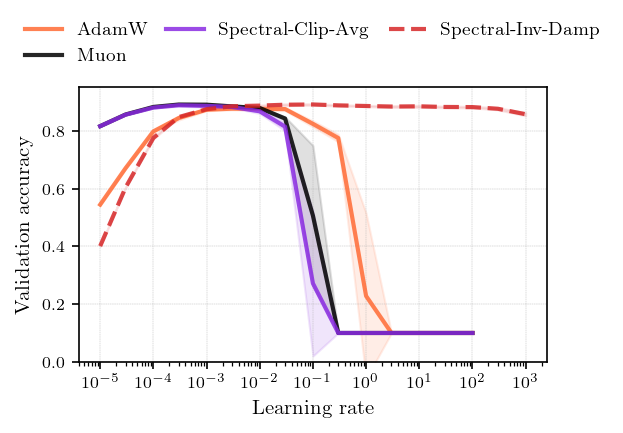

In [4]:
fig, ax = plot_val_acc_vs_lr(R, ylim=[0., 0.95])

## Validation accuracy vs epoch at best LR (mean ± std over 5 seeds)

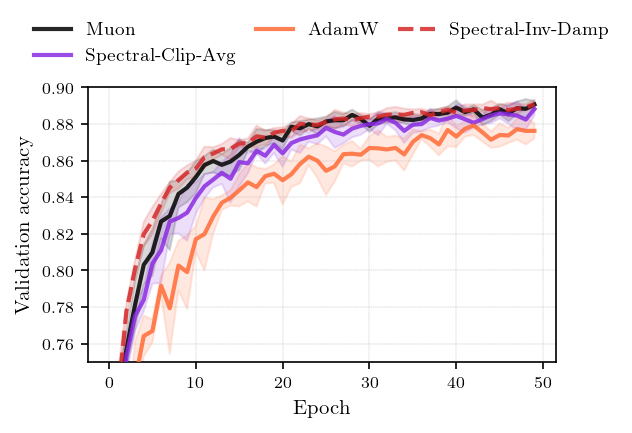

In [5]:
fig, ax = plot_val_acc_vs_epoch_seeds(R, ylim=[0.75, 0.9])

## Best config per method (mean ± std over 5 seeds)

In [6]:
rows = []
for name in R.id_df["name"].unique():
    sub = R.base_df[R.base_df["name"] == name]
    final = sub[sub["epoch"] == sub["epoch"].max()]
    best_row = final.loc[final["val_score"].idxmax()]
    conf = dict(item.split("=") for item in best_row["id"].split(":"))
    rows.append({
        "Method": _display_name(name),
        "lr": float(conf["lr"]),
        "Val Acc (mean)": f'{best_row["val_score"]:.4f}',
        "Val Acc (std)": f'{best_row["val_score_std"]:.4f}',
        "Val Loss (mean)": f'{best_row["val_loss"]:.4f}',
        "Val Loss (std)": f'{best_row["val_loss_std"]:.4f}',
    })

table = pd.DataFrame(rows).sort_values("Val Acc (mean)", ascending=False).reset_index(drop=True)
table

,Method,lr,Val Acc (mean),Val Acc (std),Val Loss (mean),Val Loss (std)
0,Spectral-Inv-Damp,0.1000,0.8908,0.0025,0.3700,0.0044
1,Muon,0.0003,0.8906,0.0020,0.4339,0.0153
2,Spectral-Clip-Avg,0.0003,0.8881,0.0036,0.4213,0.0185
3,AdamW,0.0030,0.8762,0.0042,0.4593,0.0136
